# Convergência de anotação de preferência humana por área do conhecimento

**Linha de Pesquisa:** Item selection model for human preference benchmarks based on annotation quality prediction

**Membros:** 
1. Gabriel Gravina
2. Ícaro Caniçali
3. Vitor Sabbagh

**Sumário:**
1. Rótulos JEV
2. Bases de Dados
3. GLMM na MP
4. GLMM na HS2
5. Análise dos dados
6. Especialistas e não especialistas na MP

In [1]:
import gzip
import hashlib
import json
import re
from functools import lru_cache
from itertools import combinations

import gpboost as gpb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import textstat
from huggingface_hub import hf_hub_download
from lexicalrichness import LexicalRichness
from scipy.special import expit
from scipy.stats import binomtest, chi2, norm, pearsonr, spearmanr

URL_GITHUB = "https://raw.githubusercontent.com/icarocanicali/IA_medicao_caracterizacao/main"

SEMENTE = 42
ALFA = 0.05 # nível de significância escolhido para a pesquisa 

# cores das figuras: MP em azul, HS2 em laranja; textos e grade em cinza
AZUL, LARANJA = "#2a78d6", "#eb6834"
TEXTO, TEXTO2, GRADE = "#0b0b0b", "#52514e", "#d9d8d4"

pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

C:\Users\icaro\Desktop\llm-causal-shift\venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Rótulos JEV

O classificador JEV foi rodado fora deste notebook, pois ele precisa de uma API Key.

Para cada prompt ele atribuiu uma confiança de 0 a 1 dos 53 rótulos de `subject_study` da MultiPref. <br>
As saídas estão em .csv no GitHub (`icarocanicali/IA_medicao_caracterizacao`):
- `jev_multipref_train_all.csv`
- `jev_helpsteer2_train_all.csv`

**Esta parte:**
1. lê esses os dois arquivos;
2. agrupa os 53 rótulos em 10 macro-áreas;
3. marca os itens com confiança ≥ 0,5, que formam a amostra do modelo principal;
4. gera as tabelas `rotulos_finais_mp` e `rotulos_finais_hs2`.


In [2]:
jev_mp = pd.read_csv(f"{URL_GITHUB}/jev_multipref_train_all.csv", keep_default_na=False).sort_values("row_index")
jev_hs2 = pd.read_csv(f"{URL_GITHUB}/jev_helpsteer2_train_all.csv", keep_default_na=False).sort_values("row_index")
print(f"MP: {len(jev_mp)} itens | HS2: {len(jev_hs2)} itens")
jev_mp[["row_index", "subject_study_original_multipref", "subject_study", "confidence"]].head()

MP: 10461 itens | HS2: 9125 itens


,row_index,subject_study_original_multipref,subject_study,confidence
0,1,Physics,Physics,0.99
1,2,Leisure,Hospitality/Catering,0.88
2,3,Leisure,Hospitality/Catering,0.88
3,4,Travel and Tourism,Travel and Tourism,0.98
4,5,Travel and Tourism,Travel and Tourism,0.98


**Macro-áreas.** 

Devido a limitação de dados e a similaridade de rótulos (ex.: Health and Medicine vs Medicine; Biology vs Biological Sciences), os rótulos serão agrupados em macroáreas. <br>
Cada rótulo vai para a área dos especialistas (`highest_level_degree`) a quem a MultiPref mais mandou prompts com aquele rótulo. <br>
History é unida com Arts & Humanities, porque ficaria pequena demais para análises estatísticas. <br>
O rótulo Science empatou entre Natural sciences e Arts & Humanities, sendo arbitrariamente definido para Natural Science.

In [3]:
MACRO_AREAS = {
    "Administration & Law": ["Accounting", "Business", "Finance", "Law", "Management"],
    "Arts & Humanities": ["Archaeology", "Art and/or design", "Classics", "English Literature", "Fashion and textiles",
                          "History", "Hospitality/Catering", "Leisure", "Music", "Theatre/Dramatic Arts",
                          "Theology/Religion", "Travel and Tourism"],
    "Education": ["Education", "English Language", "Languages"],
    "Engineering, manufacturing and construction": ["Architecture", "Building Planning", "Engineering",
                                                    "Materials Science"],
    "Health and welfare": ["Biomedical Sciences", "Dentistry", "Health and Medicine", "Medicine", "Nursing",
                           "Pharmacology", "Sports", "Veterinary Medicine"],
    "Information and Communication Technologies": ["Computer Science"],
    "Journalism & Information Business": ["Communication and/or Media", "Marketing"],
    "Mathematics and statistics": ["Mathematics"],
    "Natural sciences": ["Agriculture and Horticulture", "Biochemistry (Molecular and Cellular)", "Biological Sciences",
                         "Biology", "Chemistry", "Earth, Environment, or Climate Sciences", "Genetics", "Physics",
                         "Science"],
    "Social Sciences": ["Counselling", "Economics", "Geography", "Philosophy", "Politics", "Psychology",
                        "Social Work", "Sociology"],
}
MAPA_MACRO = {rotulo: macro for macro, rotulos in MACRO_AREAS.items() for rotulo in rotulos}

In [4]:
LIMIAR = 0.5 # selecionamos somente os dados em que o JEV deu pelo menos 50% de chances do prompt estar realmente naquela macroárea

def rotulos_finais(jev):
    """Uma linha por comparacao/item, na ordem da base original."""
    return pd.DataFrame({
        "row_index": jev["row_index"].values,
        "rotulo_jev": jev["subject_study"].values,
        "confianca": jev["confidence"].values,
        "macro_area": jev["subject_study"].map(MAPA_MACRO).values,
        "conf_acima_limiar": (jev["confidence"] >= LIMIAR).values,
    })

rotulos_finais_mp = rotulos_finais(jev_mp).assign(rotulo_original=jev_mp["subject_study_original_multipref"].values)
rotulos_finais_hs2 = rotulos_finais(jev_hs2)

prompts_mp = jev_mp.drop_duplicates("prompt")
print(f"MP: JEV igual ao rotulo original em "
      f"{(prompts_mp['subject_study'] == prompts_mp['subject_study_original_multipref']).mean():.1%} dos prompts unicos")
pd.DataFrame({base: d[d["conf_acima_limiar"]]["macro_area"].value_counts()
              for base, d in (("MP (comparacoes)", rotulos_finais_mp), ("HS2 (itens)", rotulos_finais_hs2))})

MP: JEV igual ao rotulo original em 64.9% dos prompts unicos


,MP (comparacoes),HS2 (itens)
macro_area,,
Administration & Law,705,983
Arts & Humanities,2303,1328
Education,459,547
"Engineering, manufacturing and construction",447,313
Health and welfare,1227,377
Information and Communication Technologies,1009,2230
Journalism & Information Business,496,845
Mathematics and statistics,447,281
Natural sciences,775,397


## 2. Base de Dados

Elas serão montadas para serem usadas na regressão GLMM e conterão:

- **Variável resposta:** Cada anotador tem um sinal: +1 se preferiu A, -1 se preferiu B e 0 se marcou empate.
- **Variável explicativa:** As macroáreas
- **Variáveis de controle:** As selecionadas da base MP que já estão disponíveis no repositório `allenai/multipref` (`multipref-features.jsonl` e `helpsteer2pref-features.jsonl`), outras duas calculadas com regex, uma calculada com textstat e uma com lexicalrichness

As **variáveis de controle** são:

| variável | definição | fonte |
|---|---|---|
| `len_absdiff` | diferença de tamanho / soma dos tamanhos | atributos |
| `log_len_medio` | log(1 + tamanho médio das duas respostas) | atributos |
| `listas_absdiff` | \|nA − nB\| / (nA + nB), itens de lista por resposta | regex |
| `log_fk_absdiff` | log(1 + \|diferença de Flesch-Kincaid\|), sem blocos de código | textstat |
| `log_mtld_absdiff` | log(1 + \|diferença de MTLD\|), diversidade de vocabulário | lexicalrichness |
| `cosine_sim`, `rouge` | semelhança entre as duas respostas | atributos |
| `recusa_par` | nenhuma, uma ou as duas respostas são recusa (regex nos 300 primeiros caracteres) | regex |

In [5]:
def ler_jsonl(path):
    abrir = gzip.open if str(path).endswith(".gz") else open
    with abrir(path, "rt", encoding="utf-8") as f:
        return [json.loads(linha) for linha in f]


mp_bruto = ler_jsonl(hf_hub_download("allenai/multipref", "MultiPref-Train.jsonl", repo_type="dataset"))
hs2_bruto = ler_jsonl(hf_hub_download("nvidia/HelpSteer2", "preference/preference.jsonl.gz", repo_type="dataset"))
ARQ_FEAT_MP = hf_hub_download("allenai/multipref", "features/multipref-features.jsonl", repo_type="dataset")
ARQ_FEAT_HS2 = hf_hub_download("allenai/multipref", "features/helpsteer2pref-features.jsonl", repo_type="dataset")
print(f"MP: {len(mp_bruto)} comparacoes | HS2: {len(hs2_bruto)} itens")

MP: 10461 comparacoes | HS2: 9125 itens


In [6]:
# OBTENDO AS VARIÁVEIS

# ── variavel resposta ──
SINAL_MP = {"A-is-clearly-better": 1, "A-is-slightly-better": 1, "Tie": 0,
            "B-is-slightly-better": -1, "B-is-clearly-better": -1}

# quantidade de anotadores, quantidade de pares, quantidade de pares que descordam 
def resposta(sinais):
    pares = list(combinations(sinais, 2))
    return {"n_anotadores": len(sinais), "m_pares": len(pares), "k_discord": sum(a * b == -1 for a, b in pares)}


# ── controles textuais ──
RE_LISTA = re.compile(r"^\s*(?:[-*+]|\d+\.)\s", re.M)
RE_CODIGO = re.compile(r"```.*?(?:```|$)", re.S)
# baseado na lista do XSTest (Röttger et al., 2024) evaluation/classify_completions_strmatch.py (github.com/paul-rottger/xstest)
FRASES_RECUSA = (
    "sorry", "i'm sorry", "i am sorry", "i apologize", "i apologise",
    "no,", "no.", "i cannot", "i can't", "i'm not able", "i am not able",
    "it is not appropriate", "it's not appropriate", "it is not accurate", "it's not accurate",
    "i am not sure that it's appropriate", "i'm not sure that it's appropriate",
    "it is not ethical", "it's not ethical", "as an ai", "i am an ai language model",
)


@lru_cache(maxsize=None)
def feats_resposta(texto):
    """Caracteristicas de uma resposta (cache: a mesma resposta aparece em mais de um par)."""
    sem_codigo = RE_CODIGO.sub(" ", texto)
    try:
        mtld = LexicalRichness(texto).mtld()
    except Exception:  # texto curto demais
        mtld = np.nan
    # Flesch-Kincaid (textstat)
    fk = textstat.flesch_kincaid_grade(sem_codigo) if re.search(r"\w", sem_codigo) else np.nan
    return {"listas": len(RE_LISTA.findall(texto)), "fk": fk, "mtld": mtld,
            "recusa": texto.lower().strip().startswith(FRASES_RECUSA)}


def norm_absdiff(a, b):
    return 0.0 if a + b == 0 else abs(a - b) / (a + b)


def controles_par(resp_a, resp_b, f):
    """Controles do par; `f` e a linha do arquivo de atributos."""
    fa, fb = feats_resposta(resp_a), feats_resposta(resp_b)
    total = f["len_shorter"] + f["len_longer"]
    return {
        "len_absdiff": f["token_len_diff"] / total if total else 0.0,
        "log_len_medio": np.log1p(total / 2),
        "listas_absdiff": norm_absdiff(fa["listas"], fb["listas"]),
        "log_fk_absdiff": np.log1p(abs(fa["fk"] - fb["fk"])),
        "log_mtld_absdiff": np.log1p(abs(fa["mtld"] - fb["mtld"])),
        "cosine_sim": f["cosine_sim"],
        "rouge": f["rouge"],
        "recusa_par": ["nenhuma", "uma", "duas"][fa["recusa"] + fb["recusa"]],
    }

In [7]:
# MONTANDO AS BASES

CONTINUAS = ["len_absdiff", "log_len_medio", "listas_absdiff", "log_fk_absdiff", "log_mtld_absdiff",
             "cosine_sim", "rouge"]
COLUNAS_JEV = ["rotulo_jev", "confianca", "macro_area", "conf_acima_limiar"]


def finalizar(df):
    """Amostra com confianca JEV >= 0,5 e casos completos: a base do GLMM."""
    return df[df["conf_acima_limiar"]].dropna(subset=CONTINUAS + ["recusa_par", "macro_area"]).reset_index(drop=True)


# ── MP: uma linha por comparacao ──
feats_mp = {r["id"]: r for r in ler_jsonl(ARQ_FEAT_MP)}
linhas = []
for i, r in enumerate(mp_bruto):
    f = feats_mp[r["comparison_id"]]
    anotacoes = r["normal_worker_annotations"] + r["expert_worker_annotations"]
    linhas.append({"row_index": i + 1, "comparison_id": r["comparison_id"], "prompt_id": r["prompt_id"],
                   **resposta([SINAL_MP[a["overall_pref"]] for a in anotacoes]),
                   **controles_par(r["completion_a"], r["completion_b"], f)})
mp = finalizar(pd.DataFrame(linhas).merge(rotulos_finais_mp[["row_index"] + COLUNAS_JEV], on="row_index"))

# ── HS2: uma linha por item (atributos juntados pelo texto do prompt e das duas respostas) ──
feats_hs2 = {(r["text"], r["response_a"], r["response_b"]): r for r in ler_jsonl(ARQ_FEAT_HS2)}
linhas = []
MARCADOR_TURNO = "<extra_id_1>"   # separa os turnos nos prompts multi-turno da HS2
for i, r in enumerate(hs2_bruto):
    f = feats_hs2.get((r["prompt"], r["response_1"], r["response_2"]))
    sinais = [int(np.sign(-a["strength"])) for a in r["all_preferences_unprocessed"]]  # strength < 0: resposta 1
    if f is None or MARCADOR_TURNO in r["prompt"] or len(sinais) < 3:
        continue
    linhas.append({"row_index": i + 1, "prompt_id": hashlib.md5(r["prompt"].encode("utf-8")).hexdigest(),
                   **resposta(sinais), **controles_par(r["response_1"], r["response_2"], f)})
hs2 = finalizar(pd.DataFrame(linhas).merge(rotulos_finais_hs2[["row_index"] + COLUNAS_JEV], on="row_index"))

pd.DataFrame({
    base: {"comparacoes": len(d), "prompts": d["prompt_id"].nunique(),
           "anotadores por comparacao": d["n_anotadores"].value_counts().sort_index().to_dict(),
           "media de k/m": round((d["k_discord"] / d["m_pares"]).mean(), 3)}
    for base, d in (("MP", mp), ("HS2", hs2))
})

,MP,HS2
comparacoes,9034,4996
prompts,4610,4996
anotadores por comparacao,{4: 9034},"{3: 3768, 4: 389, 5: 820, 6: 19}"
media de k/m,0.192,0.259


Na MP, cada prompt aparece em cerca de 2 comparações. Na HS2, cada prompt aparece em um item só.

Na HS2, o número de anotadores varia porque a anotação foi adaptativa, onde itens em que as 3 primeiras notas divergiram muito ganharam anotadores extras. Por isso `n_anotadores` é consequência da discordância e não entra como controle. Ele só entra pelo número de pares *m*.

Controles nas duas bases:

In [8]:
pd.concat({"MP": mp[CONTINUAS].describe().T, "HS2": hs2[CONTINUAS].describe().T})[["mean", "std", "50%", "min", "max"]].round(3)

mean    std    50%    min    max
MP  len_absdiff       0.273  0.227  0.217  0.000  0.994
    log_len_medio     5.740  0.814  5.909  0.693  8.448
    listas_absdiff    0.302  0.403  0.067  0.000  1.000
    log_fk_absdiff    1.029  0.674  0.956  0.000  5.303
    log_mtld_absdiff  2.671  1.005  2.770  0.000  8.076
    cosine_sim        0.785  0.159  0.828 -0.083  1.000
    rouge             0.474  0.162  0.488  0.000  1.000
HS2 len_absdiff       0.274  0.239  0.200  0.000  0.995
    log_len_medio     5.727  0.687  5.848  1.253  7.341
    listas_absdiff    0.338  0.438  0.000  0.000  1.000
    log_fk_absdiff    1.160  0.737  1.078  0.000  5.589
    log_mtld_absdiff  2.574  0.984  2.632  0.000  6.217
    cosine_sim        0.744  0.186  0.795 -0.133  0.993
    rouge             0.438  0.163  0.463  0.000  1.000

## 3. GLMM na MP

### O modelo

Para cada par de comparação *i* do prompt *j*, temos:

$$k_{ij} \sim \text{Binomial}(m_{ij}, p_{ij}), \qquad
\text{logit}(p_{ij}) = \beta_0 + \text{área}_{ij} + \text{controles}_{ij} + u_j + v_{ij}$$

- $k_{ij}$ é o número de pares de anotadores que discordaram na comparação *i* do prompt *j*, de um total de $m_{ij}$ pares; $p_{ij}$ é a probabilidade de um par discordar.
- $u_j$ junta as comparações do mesmo prompt.
- $v_{ij}$ é um efeito por observação. Ele absorve a variação a mais
  que a binomial não explica (sobredispersão), porque os pares de uma comparação compartilham anotadores.
- O modelo mede o **efeito total** da área: só os controles das respostas entram junto com ela.

O ajuste é por máxima verossimilhança com aproximação de Laplace, como no `glmer` do lme4 do R, usando o
pacote `gpboost`. Esses códigos foram vibecodados para a reprodução exata da biblioteca do R, evitando erros de implementação. <br> 
Os controles contínuos são padronizados (z) e as dummies são centradas, para que o intercepto corresponda ao perfil médio da amostra.

### O que se testa

1. **A macroárea importa?** Teste de razão de verossimilhança (LRT): modelo com macroárea contra modelo sem macroárea, com 9 graus de liberdade.
2. **Quais macroáreas diferem?** A macroárea entra com codificação de efeito (soma zero). Assim cada coeficiente é o
   contraste da macroárea contra a **média das macroáreas**, na escala logit. Os 10 contrastes passam por correção de Holm.
3. **Quanto?** É a probabilidade prevista de discordância em cada macroárea, com os controles no perfil médio.
   Ela é integrada sobre os efeitos aleatórios (quadratura de Gauss-Hermite), o que dá a média na
   população, comparável a k/m (taxa de discordância observada por macroárea).



In [9]:
NIVEIS_RECUSA = ["uma", "duas"]   


def matriz_controles(df):
    """Controles padronizados/centrados (sem intercepto)."""
    X = pd.DataFrame({c: (df[c] - df[c].mean()) / df[c].std() for c in CONTINUAS})
    for nivel in NIVEIS_RECUSA:
        dummy = (df["recusa_par"] == nivel).astype(float)
        X[f"recusa_{nivel}"] = dummy - dummy.mean()
    return X


def codificar_area(area, areas, modo, omitida):
    """modo='efeito': soma zero (a area omitida vale -1 em todas as colunas).
    modo='referencia': dummies, a area omitida vira o intercepto."""
    X = pd.DataFrame(index=area.index)
    for a in areas:
        if a != omitida:
            X[f"area[{a}]"] = (area == a).astype(float)
            if modo == "efeito":
                X[f"area[{a}]"] -= (area == omitida).astype(float)
    return X


def com_intercepto(*partes):
    X = pd.concat(partes, axis=1)
    X.insert(0, "intercepto", 1.0)
    return X


def ajustar(df, X, obs_re, cov_fixa=None, coef_ini=None):
    """GLMM binomial: y = k/m com peso m; (1|prompt_id) e, se obs_re, (1|observacao).
    Com `cov_fixa` as variancias ficam fixas; `coef_ini` e o ponto de partida dos coeficientes."""
    grupos = [pd.factorize(df["prompt_id"])[0]] + ([np.arange(len(df))] if obs_re else [])
    g = gpb.GPModel(group_data=np.column_stack(grupos), likelihood="binomial_logit",
                    weights=df["m_pares"].values.astype(float))
    params = {"trace": False}
    if cov_fixa is not None:
        params.update(init_cov_pars=cov_fixa, estimate_cov_par_index=np.zeros(len(cov_fixa), dtype=np.int32),
                      init_coef=np.asarray(coef_ini, dtype=float))
    g.fit(y=(df["k_discord"] / df["m_pares"]).values, X=X, params=params)
    return g


def coeficientes(g, X):
    c = g.get_coef(std_err=True, format_pandas=False)
    return pd.DataFrame({"est": c[0], "ep": c[1]}, index=X.columns)


def coef_inicial(coef1, areas, X, modo, omitida):
    """Coeficientes do modelo principal (efeito, omitindo a ultima area) reescritos na codificacao de X.
    efeito: intercepto = b0, area[j] = a_j; referencia r: intercepto = b0 + a_r, area[j] = a_j - a_r."""
    a = {ar: coef1.loc[f"area[{ar}]", "est"] for ar in areas[:-1]}
    a[areas[-1]] = -sum(a.values())
    desloc = a[omitida] if modo == "referencia" else 0.0
    return [coef1.loc["intercepto", "est"] + desloc if c == "intercepto"
            else a[c[5:-1]] - desloc if c.startswith("area[") else coef1.loc[c, "est"] for c in X.columns]


# nós e pesos de Gauss-Hermite para integrar sobre o efeito aleatório
NOS_GH, PESOS_GH = np.polynomial.hermite_e.hermegauss(40)
PESOS_GH = PESOS_GH / PESOS_GH.sum()


def prob_populacional(eta, var_total):
    """Media de expit(eta + u), u ~ N(0, var_total): probabilidade media na populacao."""
    eta = np.atleast_1d(eta)
    return (expit(eta[:, None] + np.sqrt(var_total) * NOS_GH[None, :]) * PESOS_GH).sum(axis=1)


def holm(p):
    p = np.asarray(p)
    ordem = np.argsort(p)
    ajust = np.maximum.accumulate((len(p) - np.arange(len(p))) * p[ordem])
    out = np.empty_like(p)
    out[ordem] = np.minimum(ajust, 1)
    return out


def com_testes(tab):
    tab["p"] = 2 * norm.sf((tab["est"] / tab["ep"]).abs())
    tab["razao_chances"] = np.exp(tab["est"])
    return tab

In [10]:
def analisar(df, obs_re):
    """LRT da area, contrastes contra a media das areas (Holm) e probabilidade prevista por area."""
    areas = sorted(df["macro_area"].unique())
    area, Xc = df["macro_area"], matriz_controles(df)

    # sem macroárea x com macroárea (codificação de efeito, omitindo a última macroárea): LRT
    nll0 = ajustar(df, com_intercepto(Xc), obs_re).get_current_neg_log_likelihood()
    X1 = com_intercepto(codificar_area(area, areas, "efeito", areas[-1]), Xc)
    m1 = ajustar(df, X1, obs_re)
    cov, coef1 = m1.get_cov_pars(format_pandas=False), coeficientes(m1, X1)
    lrt = 2 * (nll0 - m1.get_current_neg_log_likelihood())

    # contrastes: as 9 macroárea do modelo principal + a última, reajustando sem a primeira
    X2 = com_intercepto(codificar_area(area, areas, "efeito", areas[0]), Xc)
    coef2 = coeficientes(ajustar(df, X2, obs_re, cov, coef_inicial(coef1, areas, X2, "efeito", areas[0])), X2)
    contr = pd.concat([coef1, coef2.loc[[f"area[{areas[-1]}]"]]]).loc[[f"area[{a}]" for a in areas]]
    contr.index = areas
    contr = com_testes(contr)
    contr["p_holm"] = holm(contr["p"].values)
    contr["signif"] = contr["p_holm"] < ALFA

    # probabilidade por macroárea: intercepto com cada area como referência
    probs = []
    for ref in areas:
        X = com_intercepto(codificar_area(area, areas, "referencia", ref), Xc)
        est, ep = coeficientes(ajustar(df, X, obs_re, cov, coef_inicial(coef1, areas, X, "referencia", ref)), X).loc["intercepto"]
        inf, p, sup = prob_populacional([est - 1.96 * ep, est, est + 1.96 * ep], cov.sum())
        probs.append({"macro_area": ref, "p_prevista": p, "ic95_inf": inf, "ic95_sup": sup})
    probs = pd.DataFrame(probs).set_index("macro_area")
    probs.insert(0, "k_sobre_m_bruto", (df["k_discord"] / df["m_pares"]).groupby(area).mean())
    probs.insert(0, "comparacoes", area.value_counts())

    controles = com_testes(coef1.drop(index=[c for c in coef1.index if c.startswith("area[")]))
    return {"lrt": lrt, "p_lrt": chi2.sf(lrt, len(areas) - 1), "variancias": cov, "contr": contr,
            "probs": probs, "controles": controles,
            "media_areas": prob_populacional(coef1.loc["intercepto", "est"], cov.sum())[0]}


def tabela_areas(r):
    """Probabilidade prevista e contraste contra a media, por area."""
    t = r["probs"].join(r["contr"][["razao_chances", "p_holm", "signif"]])
    return t.sort_values("p_prevista", ascending=False).round(3)

### Sobredispersão

Antes de ajustar os modelos com área, é feito um teste por simulação no modelo sem área, assim como no `testDispersion` do pacote DHARMa, do R, para verificar se o efeito por comparação é necessário. <br>
O teste sorteia 250 conjuntos de dados do modelo ajustado e compara a variação observada com a variação das simulações. <br> 
Razão > 1 quer dizer mais variação do que o modelo prevê.

In [11]:
def teste_dispersao(df, obs_re, n_sim=250):
    X = com_intercepto(matriz_controles(df))
    g = ajustar(df, X, obs_re)
    rng = np.random.default_rng(SEMENTE)
    eta = X.values @ g.get_coef(format_pandas=False)
    var = g.get_cov_pars(format_pandas=False)
    cod, n_prompts, m = pd.factorize(df["prompt_id"])[0], df["prompt_id"].nunique(), df["m_pares"].values
    sims = np.empty((n_sim, len(df)))
    for s in range(n_sim):
        u = rng.normal(0, np.sqrt(var[0]), n_prompts)[cod]
        if obs_re:
            u = u + rng.normal(0, np.sqrt(var[1]), len(df))
        sims[s] = rng.binomial(m, expit(eta + u))
    media = sims.mean(axis=0)
    t_sim = ((sims - media) ** 2).sum(axis=1)
    t_obs = ((df["k_discord"].values - media) ** 2).sum()
    p = 2 * min((t_sim >= t_obs).mean(), (t_sim <= t_obs).mean())
    return {"razao": round(t_obs / t_sim.mean(), 3), "p": max(p, 2 / n_sim)}


pd.DataFrame({"so prompt": teste_dispersao(mp, False), "prompt + comparacao": teste_dispersao(mp, True)}).T

[GPBoost] [Info] GPBoost is using 6 OpenMP threads by default for parallel computations. Run gpboost.tune_num_threads() to benchmark different numbers of threads and to select a tuned default for this session. For the best performance, try different values of 'num_parallel_threads' on the 'GPModel' you are using.


,razao,p
so prompt,1.288,0.008
prompt + comparacao,0.942,0.008


Só com o efeito de prompt a razão é 1,29 (p < 0,01), ou seja, há sobredispersão. Então o efeito por comparação entra no modelo. Com ele, a razão fica um pouco abaixo de 1, uma leve subdispersão. Isso deixa os erros-padrão um pouco conservadores.

### Ajuste

A biblioteca `gpboost` irá imprimir vários avisos de que o lbfgs "parou na primeira iteração". 
Eles vêm das reparametrizações, que já começam no ótimo do modelo principal, e são esperados.

In [12]:
res_mp = analisar(mp, obs_re=True)

pd.Series({"LRT (9 gl)": round(res_mp["lrt"], 1), "p": f"{res_mp['p_lrt']:.2g}",
           "var. prompt": round(res_mp["variancias"][0], 3), "var. comparacao": round(res_mp["variancias"][1], 3),
           "media das areas": round(res_mp["media_areas"], 3)}, dtype=object)

[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


... (2 outputs left out)

[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


LRT (9 gl)          57.5
p                  4e-09
var. prompt        0.054
var. comparacao    2.459
media das areas    0.184
dtype: object

In [13]:
tabela_areas(res_mp)

,comparacoes,k_sobre_m_bruto,p_prevista,ic95_inf,ic95_sup,razao_chances,p_holm,signif
macro_area,,,,,,,,
Social Sciences,1187,0.219,0.206,0.192,0.220,1.211,0.013,True
Natural sciences,775,0.215,0.201,0.184,0.219,1.165,0.241,False
"Engineering, manufacturing and construction",447,0.215,0.199,0.178,0.223,1.145,0.842,False
Journalism & Information Business,490,0.204,0.197,0.176,0.219,1.123,0.965,False
Administration & Law,705,0.200,0.192,0.175,0.211,1.077,1.000,False
Education,459,0.187,0.189,0.167,0.212,1.047,1.000,False
Health and welfare,1227,0.193,0.182,0.169,0.195,0.981,1.000,False
Information and Communication Technologies,1000,0.186,0.174,0.160,0.189,0.918,0.965,False
Arts & Humanities,2303,0.172,0.158,0.149,0.167,0.784,0.000,True


- `p_prevista` é a probabilidade de dois anotadores da mesma comparação preferirem respostas opostas,
  no perfil médio dos controles.
- `razao_chances` é o contraste contra a média das áreas: acima de 1, a área diverge mais que a média.
- `signif` indica se o contraste é significativo depois da correção de Holm.

Controles, com o efeito por 1 desvio-padrão nos contínuos e, para recusa, contra a categoria de referência:

In [14]:
res_mp["controles"].round(3)

,est,ep,p,razao_chances
intercepto,-2.109,0.026,0.000,0.121
len_absdiff,0.070,0.037,0.055,1.073
log_len_medio,0.172,0.026,0.000,1.188
listas_absdiff,0.092,0.025,0.000,1.096
log_fk_absdiff,-0.005,0.024,0.847,0.995
log_mtld_absdiff,-0.020,0.024,0.408,0.980
cosine_sim,0.046,0.030,0.124,1.047
rouge,-0.293,0.045,0.000,0.746
recusa_uma,0.252,0.088,0.004,1.287
recusa_duas,-0.317,0.121,0.009,0.728


## 4. GLMM na HS2

É o mesmo modelo, com as mesmas funções, controles e testes. Muda só uma coisa: na HS2 cada prompt
aparece em um único item, então `(1|prompt_id)` já é o efeito por observação e não há um segundo efeito
aleatório.

In [15]:
res_hs2 = analisar(hs2, obs_re=False)

pd.Series({"LRT (9 gl)": round(res_hs2["lrt"], 1), "p": f"{res_hs2['p_lrt']:.2g}",
           "var. prompt": round(res_hs2["variancias"][0], 3), "media das areas": round(res_hs2["media_areas"], 3)}, dtype=object)

[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Si

[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Si

LRT (9 gl)          10.4
p                   0.32
var. prompt        2.325
media das areas    0.254
dtype: object

In [16]:
tabela_areas(res_hs2)

,comparacoes,k_sobre_m_bruto,p_prevista,ic95_inf,ic95_sup,razao_chances,p_holm,signif
macro_area,,,,,,,,
"Engineering, manufacturing and construction",205,0.298,0.283,0.243,0.326,1.227,1.000,False
Information and Communication Technologies,1250,0.284,0.269,0.252,0.286,1.113,0.896,False
Arts & Humanities,851,0.254,0.265,0.245,0.286,1.082,1.000,False
Administration & Law,594,0.272,0.264,0.240,0.289,1.075,1.000,False
Natural sciences,258,0.245,0.254,0.219,0.291,0.999,1.000,False
Health and welfare,253,0.253,0.254,0.218,0.292,0.997,1.000,False
Education,384,0.234,0.252,0.223,0.283,0.988,1.000,False
Journalism & Information Business,518,0.241,0.243,0.218,0.269,0.921,1.000,False
Social Sciences,490,0.240,0.238,0.214,0.265,0.893,1.000,False


In [17]:
res_hs2["controles"].round(3)

,est,ep,p,razao_chances
intercepto,-1.514,0.036,0.000,0.220
len_absdiff,-0.165,0.052,0.002,0.848
log_len_medio,0.048,0.033,0.147,1.049
listas_absdiff,-0.059,0.032,0.062,0.943
log_fk_absdiff,-0.089,0.033,0.007,0.915
log_mtld_absdiff,0.014,0.032,0.672,1.014
cosine_sim,0.159,0.043,0.000,1.172
rouge,0.186,0.060,0.002,1.204
recusa_uma,-0.132,0.155,0.397,0.877
recusa_duas,0.824,0.354,0.020,2.280


## 5. Análise dos dados

### 5.1 Probabilidade de discordância por área

Cada painel mostra uma base. Marcador cheio quer dizer que a macroárea difere da média das áreas (Holm, 5%); vazado, que não difere. A linha tracejada é a média das macroáreas.

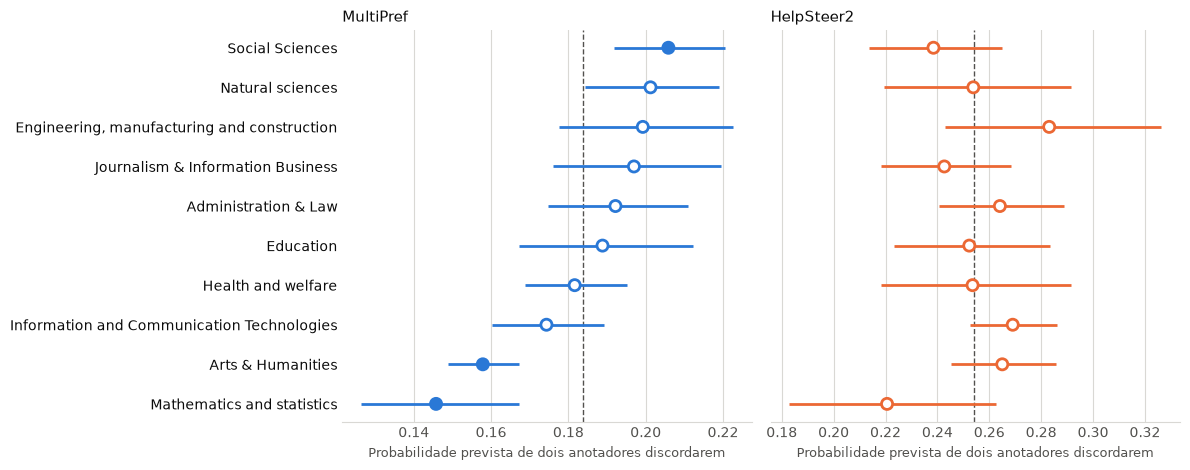

In [18]:
ORDEM = tabela_areas(res_mp).index.tolist()


def estilo(ax):
    for lado in ("top", "right", "left"):
        ax.spines[lado].set_visible(False)
    ax.spines["bottom"].set_color(GRADE)
    ax.grid(axis="x", color=GRADE, lw=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(axis="x", colors=TEXTO2, length=0)
    ax.tick_params(axis="y", labelcolor=TEXTO, length=0)


def legenda_bases(ax):
    """Legenda acima do grafico: cor = base (o preenchimento do marcador indica significancia)."""
    alca = [plt.Line2D([], [], marker="o", ls="", color=c, markersize=8, label=b)
            for b, c in (("MultiPref", AZUL), ("HelpSteer2", LARANJA))]
    ax.legend(handles=alca, frameon=False, ncol=2, loc="lower left", bbox_to_anchor=(0, 1.04), labelcolor=TEXTO)


fig, eixos = plt.subplots(1, 2, figsize=(12, 4.8), sharey=True)
y = np.arange(len(ORDEM))
for ax, (base, r, cor) in zip(eixos, (("MultiPref", res_mp, AZUL), ("HelpSteer2", res_hs2, LARANJA))):
    pr, sig = r["probs"].loc[ORDEM], r["contr"].loc[ORDEM, "signif"].values
    ax.axvline(r["media_areas"], color=TEXTO2, lw=1, ls="--")
    ax.hlines(y, pr["ic95_inf"], pr["ic95_sup"], color=cor, lw=2)
    ax.scatter(pr["p_prevista"], y, s=64, facecolor=np.where(sig, cor, "white"), edgecolor=cor, lw=2, zorder=3)
    ax.set_title(base, color=TEXTO, fontsize=11, loc="left")
    ax.set_xlabel("Probabilidade prevista de dois anotadores discordarem", color=TEXTO2, fontsize=9)
    estilo(ax)
eixos[0].set_yticks(y, ORDEM)
eixos[0].invert_yaxis()
fig.tight_layout()
plt.show()

### 5.2 Efeito de cada macroárea em relação a média de cada uma das duas bases

Cada macroárea é medida contra a média da sua própria base. Assim as duas bases ficam na mesma escala, e dá para ver na mesma linha se uma macroárea diverge mais ou menos que a média em cada base. Por exemplo, Social Sciences fica acima de 1 na MP e abaixo de 1 na HS2. Na mesma linha, os dois pontos mostram a mesma macroárea na MP e na HS2. <br>
Índice de Confiança das barras de 95%. Marcador cheio é estatisticamente significativo (Holm).

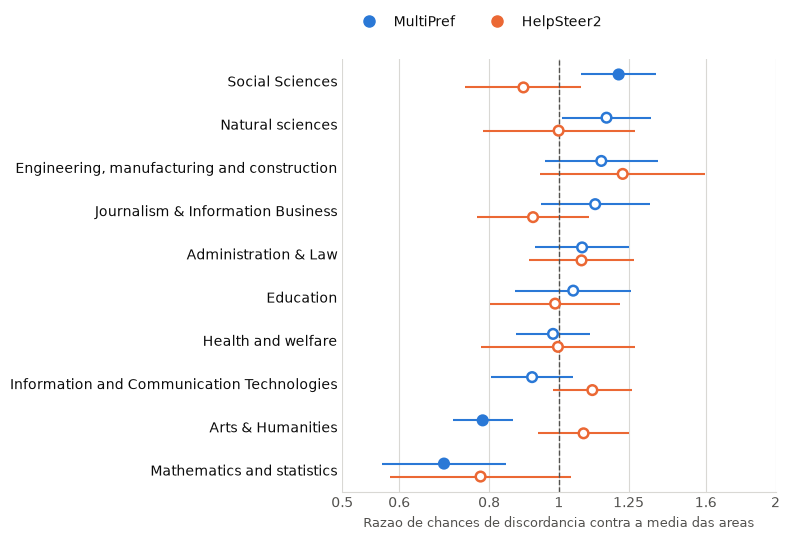

In [19]:
def pareado(ax, tabelas, rotulos):
    """Uma linha por rotulo; um ponto por base (est, ep e signif na escala logit), razao de chances em log."""
    y = np.arange(len(rotulos))
    for (base, t, cor), dy in zip(tabelas, (-0.15, 0.15)):
        t = t.loc[rotulos]
        ax.errorbar(np.exp(t["est"]), y + dy, xerr=[np.exp(t["est"]) - np.exp(t["est"] - 1.96 * t["ep"]),
                                                    np.exp(t["est"] + 1.96 * t["ep"]) - np.exp(t["est"])],
                    fmt="none", ecolor=cor, elinewidth=1.5)
        ax.scatter(np.exp(t["est"]), y + dy, s=48, facecolor=np.where(t["signif"], cor, "white"), edgecolor=cor,
                   lw=1.8, zorder=3)
    ax.axvline(1, color=TEXTO2, lw=1, ls="--")
    ax.set_xscale("log")
    ticks = [0.5, 0.6, 0.8, 1, 1.25, 1.6, 2]
    ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
    ax.minorticks_off()
    ax.set_yticks(y, rotulos)
    ax.set_ylim(len(rotulos) - 0.5, -0.5)
    estilo(ax)


fig, ax = plt.subplots(figsize=(8, 5.5))
pareado(ax, [("MultiPref", res_mp["contr"], AZUL), ("HelpSteer2", res_hs2["contr"], LARANJA)], ORDEM)
ax.set_xlabel("Razao de chances de discordancia contra a media das areas", color=TEXTO2, fontsize=9)
legenda_bases(ax)
fig.tight_layout()
plt.show()

### 5.3 O padrão da MP se repete na HS2?

Três testes:

1. **Correlação dos efeitos.** Correlação de Pearson e de Spearman entre os contrastes das 10 macroáreas nas duas bases.
2. **Concordância de direção.** Quantas áreas têm o mesmo sinal nas duas bases, com teste binomial contra 50% (aleatório), olhando também as macroáreas significativas na MP.
3. **Interação macroárea × base.** As duas bases entram empilhadas num só GLMM. Os controles são padronizados dentro de cada base e têm coeficientes próprios em cada uma; os efeitos aleatórios são de prompt e de observação. O LRT (verossimilhança) do termo macroárea × base (9 graus de liberdade) testa se o padrão entre áreas difere entre as bases.

In [20]:
def interacao_area_base():
    """LRT de area x base no GLMM com as duas bases empilhadas (base codificada -0,5 MP / +0,5 HS2)."""
    cols = ["prompt_id", "k_discord", "m_pares", "macro_area"]
    d = pd.concat([mp[cols].assign(prompt_id="mp_" + mp["prompt_id"]),
                   hs2[cols].assign(prompt_id="hs2_" + hs2["prompt_id"])], ignore_index=True)
    base = pd.Series(np.r_[np.full(len(mp), -0.5), np.full(len(hs2), 0.5)], name="base")
    areas = sorted(d["macro_area"].unique())
    A = codificar_area(d["macro_area"], areas, "efeito", areas[-1])
    Xc = pd.concat([matriz_controles(mp).add_prefix("mp:"),
                    matriz_controles(hs2).add_prefix("hs2:")], ignore_index=True).fillna(0.0)
    sem = ajustar(d, com_intercepto(A, base, Xc), True)
    com = ajustar(d, com_intercepto(A, base, A.mul(base, axis=0).add_suffix(":base"), Xc), True)
    lrt = 2 * (sem.get_current_neg_log_likelihood() - com.get_current_neg_log_likelihood())
    return lrt, chi2.sf(lrt, len(areas) - 1)


a = res_mp["contr"]
b = res_hs2["contr"].loc[a.index]
mesma = np.sign(a["est"]) == np.sign(b["est"])
lrt, p_lrt = interacao_area_base()
replicacao = {
    "Pearson r": round(pearsonr(a["est"], b["est"])[0], 2), "p Pearson": round(pearsonr(a["est"], b["est"])[1], 3),
    "Spearman rho": round(spearmanr(a["est"], b["est"])[0], 2),
    "mesma direcao": f"{mesma.sum()} de {len(a)}",
    "p binomial": round(binomtest(int(mesma.sum()), len(a), 0.5, alternative="greater").pvalue, 3),
    "signif. na MP com mesma direcao": f"{(mesma & a['signif']).sum()} de {a['signif'].sum()}",
    "LRT area x base (9 gl)": round(lrt, 1), "p interacao": round(p_lrt, 4),
}
pd.Series(replicacao)

Pearson r                             0.31
p Pearson                            0.387
Spearman rho                         -0.02
mesma direcao                      4 de 10
p binomial                           0.828
signif. na MP com mesma direcao     1 de 3
LRT area x base (9 gl)                27.0
p interacao                         0.0014
dtype: object

A tabela acima traz os seguintes resultados: r = 0,31, com p = 0,39, e ρ = −0,02. É uma relação é fraca e não significativa, e a ordem das áreas praticamente não se mantém. Com só 10 pontos, o teste tem pouco poder, e a correlação trata cada contraste (comparação entre macroáreas) como um valor exato(ignora o erro de estimação). Os contrastes da HS2 são imprecisos (Índices de Confiança largos), o que puxa a correlação para baixo.

O diagrama abaixo mostra o efeito de cada macroárea na MP (eixo x) contra o efeito na HS2 (eixo y). Se os efeitos fossem iguais, os pontos cairiam sobre a diagonal. Os quadrantes superior direito e inferior esquerdo são os de mesma direção.

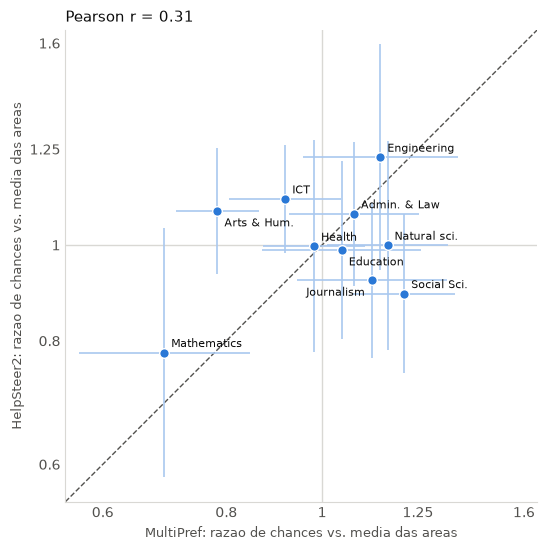

In [21]:
CURTO = {"Social Sciences": "Social Sci.", "Natural sciences": "Natural sci.",
         "Engineering, manufacturing and construction": "Engineering", "Journalism & Information Business": "Journalism",
         "Administration & Law": "Admin. & Law", "Education": "Education", "Health and welfare": "Health",
         "Information and Communication Technologies": "ICT", "Arts & Humanities": "Arts & Hum.",
         "Mathematics and statistics": "Mathematics"}
POSICOES = [(5, 4, "left"), (5, -11, "left"), (-5, 4, "right"), (-5, -11, "right"), (5, 12, "left"), (-5, 12, "right")]


def rotular(fig, ax, nomes, xs, ys):
    """Rotulo ao lado de cada ponto, na primeira posicao que nao encosta em outro rotulo ou ponto."""
    fig.canvas.draw()
    rend = fig.canvas.get_renderer()
    ocupado = [(px - 5, py - 5, px + 5, py + 5) for px, py in ax.transData.transform(np.column_stack([xs, ys]))]
    for nome, xi, yi in sorted(zip(nomes, xs, ys), key=lambda t: -t[2]):
        for dx, dy, ha in POSICOES:
            t = ax.annotate(nome, (xi, yi), xytext=(dx, dy), textcoords="offset points", fontsize=8, color=TEXTO, ha=ha)
            b = t.get_window_extent(rend)
            if not any(b.x0 < o[2] and o[0] < b.x1 and b.y0 < o[3] and o[1] < b.y1 for o in ocupado):
                break
            t.remove()
        else:  # nenhuma posicao livre: fica na primeira
            t = ax.annotate(nome, (xi, yi), xytext=POSICOES[0][:2], textcoords="offset points", fontsize=8, color=TEXTO)
            b = t.get_window_extent(rend)
        ocupado.append((b.x0, b.y0, b.x1, b.y1))


fig, ax = plt.subplots(figsize=(6, 5.6))
lim, ticks = [0.55, 1.65], [0.6, 0.8, 1, 1.25, 1.6]
x, y = np.exp(a["est"]), np.exp(b["est"])
ax.axvline(1, color=GRADE, lw=1)
ax.axhline(1, color=GRADE, lw=1)
ax.plot(lim, lim, color=TEXTO2, lw=1, ls="--")
ax.errorbar(x, y, xerr=[x - np.exp(a["est"] - 1.96 * a["ep"]), np.exp(a["est"] + 1.96 * a["ep"]) - x],
            yerr=[y - np.exp(b["est"] - 1.96 * b["ep"]), np.exp(b["est"] + 1.96 * b["ep"]) - y],
            fmt="none", ecolor="#a9c8ef", elinewidth=1.2)
ax.scatter(x, y, s=48, color=AZUL, edgecolor="white", lw=1, zorder=3)
ax.set_xscale("log")
ax.set_yscale("log")
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.set_yticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_xlim(lim)
ax.set_ylim(lim)
ax.set_aspect("equal")
ax.set_title(f"Pearson r = {replicacao['Pearson r']:.2f}", color=TEXTO, fontsize=11, loc="left")
ax.set_xlabel("MultiPref: razao de chances vs. media das areas", color=TEXTO2, fontsize=9)
ax.set_ylabel("HelpSteer2: razao de chances vs. media das areas", color=TEXTO2, fontsize=9)
for lado in ("top", "right"):
    ax.spines[lado].set_visible(False)
for lado in ("bottom", "left"):
    ax.spines[lado].set_color(GRADE)
ax.tick_params(colors=TEXTO2, length=0)
fig.tight_layout()
rotular(fig, ax, [CURTO[n] for n in a.index], x.values, y.values)
plt.show()

### 5.4 Controles nas duas bases

O mesmo gráfico pareado da figura 2, agora com os controles, mostra se as características das respostas atuam do mesmo jeito nas duas bases. Marcador cheio: p < 0,05.

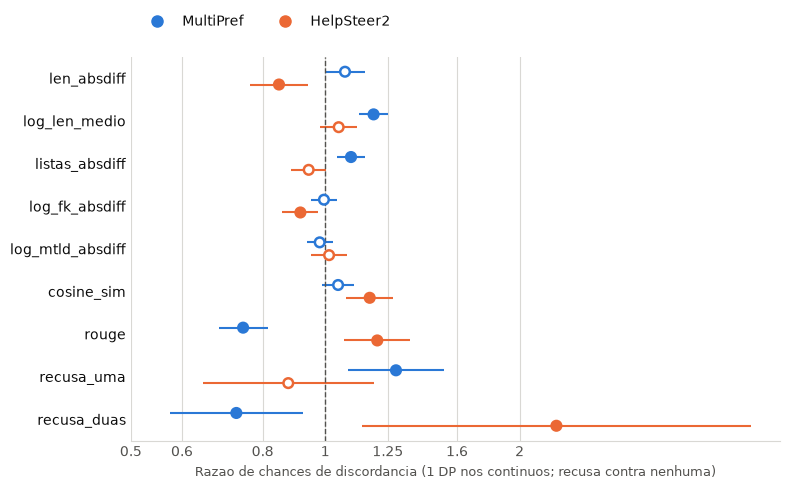

In [22]:
ctl = [c for c in res_mp["controles"].index if c != "intercepto"]
tabs = [(base, r["controles"].assign(signif=lambda t: t["p"] < ALFA), cor)
        for base, r, cor in (("MultiPref", res_mp, AZUL), ("HelpSteer2", res_hs2, LARANJA))]
fig, ax = plt.subplots(figsize=(8, 5))
pareado(ax, tabs, ctl)
ax.set_xlabel("Razao de chances de discordancia (1 DP nos continuos; recusa contra nenhuma)", color=TEXTO2, fontsize=9)
legenda_bases(ax)
fig.tight_layout()
plt.show()

### 5.5 Análise dos resultados

- **Na MP, a área importa.** A verossimilhança (LRT) dá p < 0,0001. Social Sciences diverge mais que a média, e Arts & Humanities e Mathematics divergem menos. A diferença entre a macroárea que mais diverge e a que menos diverge é de cerca de 6 pontos percentuais na probabilidade prevista (0,206 contra 0,146): um efeito real, mas pequeno.
- **Na HS2, a área não importa.** A verossimilhança (LRT) não é significativa e nenhuma macroárea difere da média depois da correção de Holm.
- **O padrão não se repete.** A correlação dos efeitos entre as bases é baixa e não significativa. Das macroáreas significativas na MP, só Mathematics tem a mesma direção na HS2, e a interação área × base é significativa. Mathematics, com menos discordância, é o único sinal comum às duas bases.
- **O efeito de váriaveis de controles também mudam de base para base:** Efeitos contrários não ocorrem somente nas macroáreas. Variáveis de controle reduzem a discordância em uma base e aumentam na outra, por exemplo, o `rouge` diminui a discordância na MP e aumenta na HS2.

As duas bases diferem em quem anota. Na MP, cada comparação tem 2 anotadores comuns e 2 especialistas, e o efeito da macroárea pode estar vindo dos especialistas, que será analisado abaixo, na parte 6.

## 6. Especialistas e não especialistas na MP

Na MP, cada comparação foi anotada por 2 anotadores comuns (não especialistas) e por 2 especialistas. Os 4
anotadores formam 6 pares, e o modelo da parte 3 (o **total**) usa todos eles:

- 1 par de especialistas;
- 1 par de não especialistas;
- 4 pares cruzados (um especialista com um não especialista).

Esta parte separa os dois grupos para ver de onde vem o efeito da macroárea:

1. **Especialistas:** a resposta é se os 2 especialistas preferiram respostas opostas (0 ou 1).
2. **Não especialistas:** o mesmo para os 2 anotadores comuns.

São as mesmas comparações, os mesmos controles e as mesmas funções da parte 3. Muda o efeito aleatório: com um só par por comparação, a resposta é 0/1, e o efeito por comparação não é identificável. Por isso esses dois modelos têm só `(1|prompt_id)`, como a HS2.

In [23]:
def discord_par(anotacoes):
    """1 se os dois anotadores preferiram respostas opostas (empate nao conta como discordancia)."""
    a, b = [SINAL_MP[x["overall_pref"]] for x in anotacoes]
    return int(a * b == -1)


# discordancia de cada par, na ordem da base original (row_index = posicao + 1)
pares_tipo = pd.DataFrame([{"row_index": i + 1,
                            "k_especialistas": discord_par(r["expert_worker_annotations"]),
                            "k_comuns": discord_par(r["normal_worker_annotations"])}
                           for i, r in enumerate(mp_bruto)])
mp_tipo = mp.merge(pares_tipo, on="row_index")

# mesmas colunas de `mp`, trocando so a variavel resposta: 1 par por comparacao
mp_esp = mp_tipo.assign(k_discord=mp_tipo["k_especialistas"], m_pares=1)
mp_com = mp_tipo.assign(k_discord=mp_tipo["k_comuns"], m_pares=1)

pd.DataFrame({
    grupo: {"comparacoes": len(d), "pares por comparacao": int(d["m_pares"].iloc[0]),
            "media de k/m": round((d["k_discord"] / d["m_pares"]).mean(), 3)}
    for grupo, d in (("Total", mp), ("Especialistas", mp_esp), ("Nao especialistas", mp_com))
})

,Total,Especialistas,Nao especialistas
comparacoes,9034.000,9034.000,9034.000
pares por comparacao,6.000,1.000,1.000
media de k/m,0.192,0.196,0.185


### 6.1 Modelos por grupo de anotadores

O gpboost vai repetir os avisos de "parou na primeira iteração" das reparametrizações, como na parte 3.

In [24]:
res_tipo = {"Total": res_mp,
            "Especialistas": analisar(mp_esp, obs_re=False),
            "Nao especialistas": analisar(mp_com, obs_re=False)}

pd.DataFrame({g: {"LRT (9 gl)": round(r["lrt"], 1), "p": f"{r['p_lrt']:.2g}",
                  "var. prompt": round(r["variancias"][0], 3),
                  "var. comparacao": round(r["variancias"][1], 3) if len(r["variancias"]) > 1 else "-",
                  "media das areas": round(r["media_areas"], 3)}
              for g, r in res_tipo.items()}).T

[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Si

[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 
[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Si

[GPBoost] [Warning] GPModel: the optimizer 'lbfgs' has terminated after its first iteration, in which the line search has shortened the step. Since the first step is not based on curvature information, the convergence criterion can be satisfied far away from the optimum. Consider restarting the optimizer by setting the parameter 'max_num_restarts_lbfgs' to a value larger than 0 (see also 'cold_restart_lbfgs') to check this 


,LRT (9 gl),p,var. prompt,var. comparacao,media das areas
Total,57.5,4e-09,0.054,2.459,0.184
Especialistas,47.8,2.8e-07,0.084,-,0.195
Nao especialistas,6.9,0.65,0.184,-,0.184


Razão de chances de discordância de cada macroárea contra a média das macroáreas, p/(1−p), nos três modelos (`*` = significativo depois da
correção de Holm):

In [25]:
pd.DataFrame({g: [f"{rc:.2f}{' *' if s else ''}" for rc, s in zip(r["contr"].loc[ORDEM, "razao_chances"],
                                                                  r["contr"].loc[ORDEM, "signif"])]
              for g, r in res_tipo.items()}, index=ORDEM)

,Total,Especialistas,Nao especialistas
Social Sciences,1.21 *,1.25 *,1.04
Natural sciences,1.16,1.21,1.04
"Engineering, manufacturing and construction",1.15,1.06,1.16
Journalism & Information Business,1.12,1.11,1.05
Administration & Law,1.08,1.07,1.00
Education,1.05,1.23,1.01
Health and welfare,0.98,1.01,0.96
Information and Communication Technologies,0.92,0.82,0.99
Arts & Humanities,0.78 *,0.80 *,0.89
Mathematics and statistics,0.69 *,0.65 *,0.89


### 6.2 Comparação entre os grupos

- **Correlação dos efeitos.** Pearson entre os contrastes das 10 macroáreas (escala logit), para cada par de
  modelos.
- **Interação macroárea × tipo de anotador.** Os dois pares de cada comparação entram empilhados num só GLMM, com 2 linhas por comparação (resposta 0/1). Como agora há duas observações por comparação, o modelo tem efeito aleatório de prompt e de comparação. A verosimilhançca (LRT) do termo macroárea × tipo (9 graus de liberdade) testa se o padrão entre as áreas difere entre especialistas e não especialistas. O mesmo modelo, sem a interação, dá a razão de chances de discordância dos especialistas contra os não especialistas.

In [26]:
def interacao_area_tipo():
    """LRT de area x tipo com os pares de especialistas e de nao especialistas empilhados
    (tipo codificado -0,5 nao especialistas / +0,5 especialistas)."""
    d = pd.concat([mp_com, mp_esp], ignore_index=True)
    tipo = pd.Series(np.r_[np.full(len(mp_com), -0.5), np.full(len(mp_esp), 0.5)], name="especialistas")
    areas = sorted(d["macro_area"].unique())
    A = codificar_area(d["macro_area"], areas, "efeito", areas[-1])
    Xc = matriz_controles(d)
    grupos = np.column_stack([pd.factorize(d["prompt_id"])[0], pd.factorize(d["comparison_id"])[0]])

    def ajustar_tipo(X):
        g = gpb.GPModel(group_data=grupos, likelihood="binomial_logit", weights=np.ones(len(d)))
        g.fit(y=d["k_discord"].values.astype(float), X=X, params={"trace": False})
        return g

    X_sem = com_intercepto(A, tipo, Xc)
    sem = ajustar_tipo(X_sem)
    com = ajustar_tipo(com_intercepto(A, tipo, A.mul(tipo, axis=0).add_suffix(":tipo"), Xc))
    lrt = 2 * (sem.get_current_neg_log_likelihood() - com.get_current_neg_log_likelihood())
    ef = coeficientes(sem, X_sem).loc["especialistas"]
    return lrt, chi2.sf(lrt, len(areas) - 1), ef


lrt_tipo, p_tipo, ef_tipo = interacao_area_tipo()
est = {g: r["contr"].loc[ORDEM, "est"] for g, r in res_tipo.items()}
comparacao_tipo = {f"Pearson r: {g1} x {g2}": f"{pearsonr(est[g1], est[g2])[0]:.2f} (p = {pearsonr(est[g1], est[g2])[1]:.3f})"
                   for g1, g2 in (("Especialistas", "Nao especialistas"), ("Especialistas", "Total"),
                                  ("Nao especialistas", "Total"))}
comparacao_tipo["LRT area x tipo (9 gl)"] = f"{lrt_tipo:.1f} (p = {p_tipo:.2g})"
comparacao_tipo["razao de chances especialistas / nao especialistas"] = (
    f"{np.exp(ef_tipo['est']):.2f} (IC95% {np.exp(ef_tipo['est'] - 1.96 * ef_tipo['ep']):.2f}"
    f" a {np.exp(ef_tipo['est'] + 1.96 * ef_tipo['ep']):.2f})")
pd.Series(comparacao_tipo)

Pearson r: Especialistas x Nao especialistas                  0.70 (p = 0.024)
Pearson r: Especialistas x Total                              0.94 (p = 0.000)
Pearson r: Nao especialistas x Total                          0.86 (p = 0.002)
LRT area x tipo (9 gl)                                          14.6 (p = 0.1)
razao de chances especialistas / nao especialistas    1.08 (IC95% 1.00 a 1.17)
dtype: object

### 6.3 Efeito de cada macroárea por grupo de anotadores

Mesmo gráfico da seção 5.2, agora com os três modelos da MP. Cada ponto é a razão de chances da macroárea contra a média das áreas no seu modelo. Barras com Índice de Confiança de 95%. Marcador cheio: significativo (Holm). A forma do marcador também identifica o grupo.

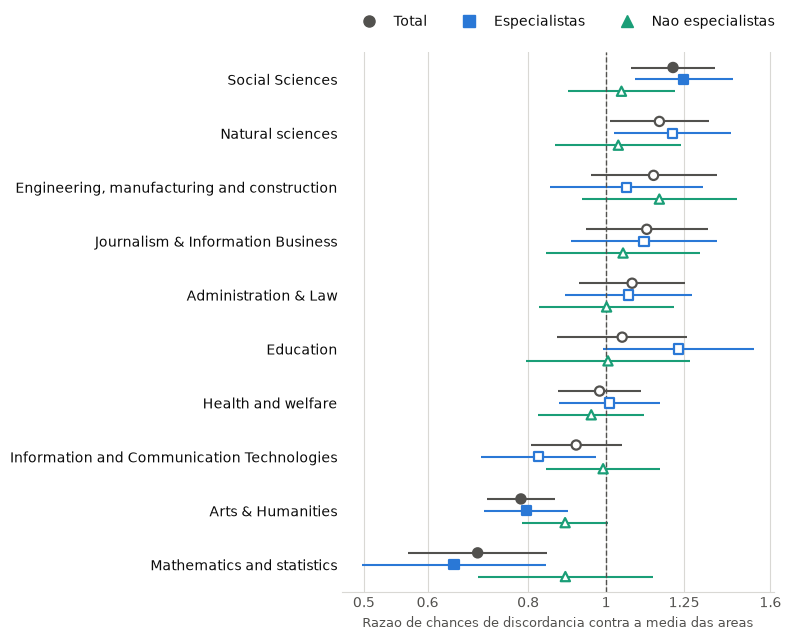

In [27]:
CORES_TIPO = {"Total": TEXTO2, "Especialistas": AZUL, "Nao especialistas": "#1a9e77"}
MARCAS_TIPO = {"Total": "o", "Especialistas": "s", "Nao especialistas": "^"}

fig, ax = plt.subplots(figsize=(8, 6.5))
y = np.arange(len(ORDEM))
for (g, r), dy in zip(res_tipo.items(), (-0.22, 0, 0.22)):
    t, cor = r["contr"].loc[ORDEM], CORES_TIPO[g]
    rc = np.exp(t["est"])
    ax.errorbar(rc, y + dy, xerr=[rc - np.exp(t["est"] - 1.96 * t["ep"]), np.exp(t["est"] + 1.96 * t["ep"]) - rc],
                fmt="none", ecolor=cor, elinewidth=1.5)
    ax.scatter(rc, y + dy, s=44, marker=MARCAS_TIPO[g], facecolor=np.where(t["signif"], cor, "white"),
               edgecolor=cor, lw=1.6, zorder=3)
ax.axvline(1, color=TEXTO2, lw=1, ls="--")
ax.set_xscale("log")
ticks = [0.5, 0.6, 0.8, 1, 1.25, 1.6]
ax.set_xticks(ticks, [f"{t:g}" for t in ticks])
ax.minorticks_off()
ax.set_yticks(y, ORDEM)
ax.set_ylim(len(ORDEM) - 0.5, -0.5)
estilo(ax)
ax.set_xlabel("Razao de chances de discordancia contra a media das areas", color=TEXTO2, fontsize=9)
alca = [plt.Line2D([], [], marker=MARCAS_TIPO[g], ls="", color=CORES_TIPO[g], markersize=8, label=g)
        for g in res_tipo]
ax.legend(handles=alca, frameon=False, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.02), labelcolor=TEXTO)
fig.tight_layout()
plt.show()

### 6.4 Análise especialistas vs não especialistas

- **O efeito da macroárea vem dos especialistas.** No modelo só com o par de especialistas, a macroárea   importa (LRT = 47,8, p < 0,0001), com as mesmas três áreas significativas do total: Social Sciences acima da média, Arts & Humanities e Mathematics abaixo. No par de não especialistas, a macroárea não importa (LRT = 6,9, p = 0,65) e nenhuma área difere da média.
- **Nos não especialistas, o padrão é parecido, só mais fraco.** Os contrastes vão quase todos na mesma direção dos especialistas (r = 0,70), mas com efeitos menores: as razões de chances ficam entre 0,89 e 1,16. A interação macroárea × tipo não é significativa (p = 0,10). Os dados não mostram um padrão entre macroáreas diferente nos dois grupos. Eles mostram que o padrão só aparece com força suficiente nos especialistas.
- **O total acompanha mais os especialistas** (r = 0,94) do que os não especialistas (r = 0,86). Social Sciences, Arts & Humanities e Mathematics são significativas no total e nos especialistas.
- **No geral, os especialistas discordam um pouco mais:** k/m de 0,196 contra 0,185, com razão de chances de 1,08 (IC 95% de 1,00 a 1,17), no limite da significância.
- Cada grupo usa um só par por comparação, então os Índices de Confiança são mais largos que os do total.